# Question
What's the probability that an AI agent that randomly moves the frogg in frogger dies within 10 seconds seconds
the random variable is time which is a continues value between 0 and 10



## trial
one trial would be the ai running in frogger until it dies with time recorded. 
all times to death are recorded and graphed


In [1]:
#!pip install gymnasium
#!pip install ale-py
#!pip install autorom[accept-rom-license]

In [2]:
import ale_py
import gymnasium as gym

# Register the ALE environments
gym.register_envs(ale_py)

# Now check the registry
gym.pprint_registry()

===== classic_control =====
Acrobot-v1                  CartPole-v0                 CartPole-v1
MountainCar-v0              MountainCarContinuous-v0    Pendulum-v1
===== phys2d =====
phys2d/CartPole-v0          phys2d/CartPole-v1          phys2d/Pendulum-v0
===== box2d =====
BipedalWalker-v3            BipedalWalkerHardcore-v3    CarRacing-v3
LunarLander-v3              LunarLanderContinuous-v3
===== toy_text =====
Blackjack-v1                CliffWalking-v1             CliffWalkingSlippery-v1
FrozenLake-v1               FrozenLake8x8-v1            Taxi-v4
===== tabular =====
tabular/Blackjack-v0        tabular/CliffWalking-v0
===== None =====
Ant-v2                      Ant-v3                      GymV21Environment-v0
GymV26Environment-v0        HalfCheetah-v2              HalfCheetah-v3
Hopper-v2                   Hopper-v3                   Humanoid-v2
Humanoid-v3                 HumanoidStandup-v2          InvertedDoublePendulum-v2
InvertedPendulum-v2         Pusher-v2             

In [3]:

import gymnasium as gym
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import time
import ale_py
import gymnasium as gym

# Register ALE environments if not done yet
gym.register_envs(ale_py)

# Correct initialization
env = gym.make(
    'ALE/Frogger-v5', 
    obs_type="rgb",  
    frameskip=4,             
    repeat_action_probability=0.25,
    full_action_space=True
)

observation, info = env.reset()

(np.float64(0.0), np.float64(1.0), np.float64(0.0), np.float64(1.0))

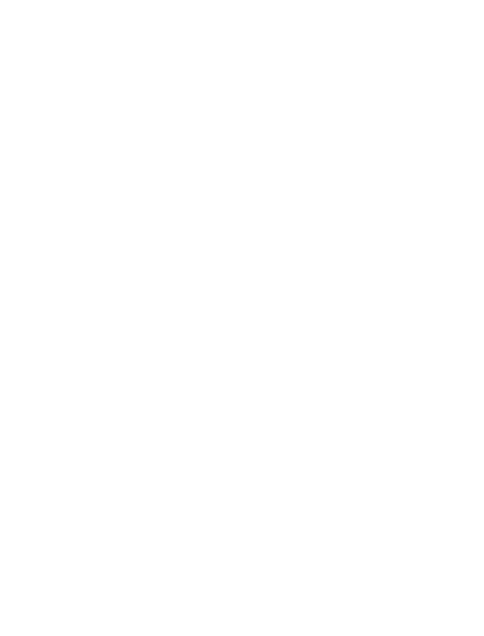

In [4]:
# Create game window
fig, ax = plt.subplots(figsize=(6, 8))
ax.axis('off')


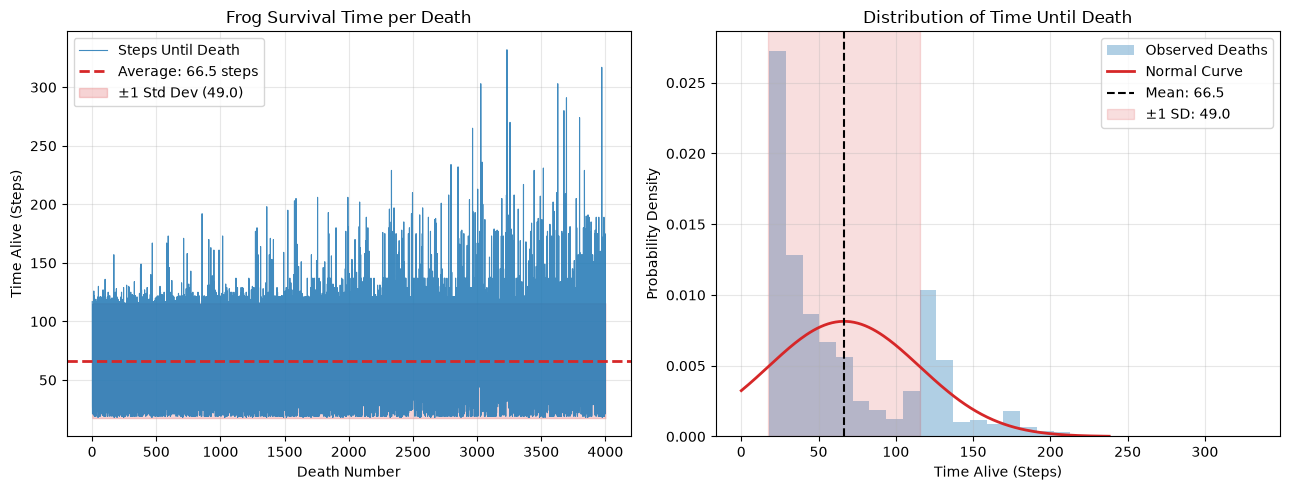

In [7]:
import time
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
import gymnasium as gym
import ale_py

gym.register_envs(ale_py)

env = gym.make('ALE/Frogger-v5', render_mode='rgb_array', frameskip=4, repeat_action_probability=0.25)

ACTION_NOOP = 0
ACTION_UP = 1
ACTION_RIGHT = 2
ACTION_LEFT = 3
ACTION_DOWN = 4

# Q-learning hyperparameters
q_table = defaultdict(lambda: np.zeros(5))
alpha = 0.2        # Learning rate
gamma = 0.95       # Discount factor
epsilon = 1.0      # Exploration rate
epsilon_min = 0.05
epsilon_decay = 0.995

# Balanced exploration so it tries waiting (NOOP) and dodging (LEFT/RIGHT)
explore_probs = [0.20, 0.35, 0.20, 0.20, 0.05]

def get_state_and_row(obs, prev_pos, last_action):
    """Finds the frog and checks 5 compact radar zones for incoming cars/logs."""
    playfield = obs[25:190, 8:152]
    h, w, _ = playfield.shape

    # Detect green pixels, then strip out wide horizontal grass banks
    green_mask = (playfield[:, :, 1] > 130) & (playfield[:, :, 0] < 115) & (playfield[:, :, 2] < 90)
    grass_rows = green_mask.sum(axis=1) > 45
    green_mask[grass_rows, :] = False

    ys, xs = np.where(green_mask)
    if len(ys) > 0:
        fy, fx = int(np.median(ys)), int(np.median(xs))
    else:
        # If standing on a masked grass bank, estimate position from last move
        fy, fx = prev_pos
        if last_action == ACTION_UP:
            fy = max(8, fy - 12)

    row = fy // 12

    def has_object(y1, y2, x1, x2):
        y1, y2 = max(0, y1), min(h, y2)
        x1, x2 = max(0, x1), min(w, x2)
        if y2 <= y1 or x2 <= x1:
            return 1  # Screen wall
        sub = playfield[y1:y2, x1:x2]
        # True for cars, trucks, logs, and turtles; False for empty black road or blue river
        obj_pixels = (sub[:, :, 0] > 45) | (sub[:, :, 1] > 65)
        return int(np.mean(obj_pixels) > 0.12)

    # Radar boxes around the frog (ahead lane + current lane sides)
    ahead_left   = has_object(fy - 20, fy - 8, fx - 26, fx - 8)
    ahead_center = has_object(fy - 20, fy - 8, fx - 8,  fx + 8)
    ahead_right  = has_object(fy - 20, fy - 8, fx + 8,  fx + 26)
    curr_left    = has_object(fy - 5,  fy + 5, fx - 22, fx - 7)
    curr_right   = has_object(fy - 5,  fy + 5, fx + 7,  fx + 22)

    state = (row, ahead_left, ahead_center, ahead_right, curr_left, curr_right)
    return state, (fy, fx), row

fig, ax = plt.subplots(figsize=(6, 8))
ax.axis('off')

num_episodes = 1000
render_every = 100
death_steps = []

for episode in range(num_episodes):
    observation, info = env.reset()
    done = False
    step_count = 0
    life_steps = 0
    current_lives = info.get('lives', 4)
    net_forward = 0
    idle_steps = 0
    total_reward = 0
    last_action = ACTION_NOOP
    frog_pos = (154, 72)

    state, frog_pos, old_row = get_state_and_row(observation, frog_pos, last_action)
    should_render = (episode + 1) % render_every == 0

    if not should_render and episode % render_every == 0:
        print(f"Training episodes {episode + 1} to {episode + render_every - 1}...")

    while not done:
        if np.random.rand() < epsilon:
            action = np.random.choice([0, 1, 2, 3, 4], p=explore_probs)
        else:
            action = int(np.argmax(q_table[state]))

        observation, reward, terminated, truncated, info = env.step(action)
        next_state, frog_pos, new_row = get_state_and_row(observation, frog_pos, action)

        custom_reward = reward
        step_count += 1
        life_steps += 1

        # Check if the frog lost a life
        new_lives = info.get('lives', current_lives)
        died = new_lives < current_lives

        if died:
            death_steps.append(life_steps)
            life_steps = 0
            current_lives = new_lives
            custom_reward -= 20.0  # Heavy penalty for getting hit
            frog_pos = (154, 72)   # Reset tracker to spawn
        else:
            # Only reward forward movement if the frog actually survived the step
            if new_row < old_row:
                custom_reward += 4.0
                net_forward += 1
                idle_steps = 0
            elif new_row > old_row:
                custom_reward -= 4.0
                net_forward -= 1
                idle_steps += 1
            elif action == ACTION_NOOP:
                # Tiny penalty for waiting so it prefers waiting over jumping into traffic
                custom_reward -= 0.1
                idle_steps += 1
            else:
                idle_steps += 1

            if idle_steps > 15:
                custom_reward -= 1.0

        done = terminated or truncated

        # Update Q-table
        best_next = 0.0 if (done or died) else np.max(q_table[next_state])
        q_table[state][action] += alpha * (custom_reward + gamma * best_next - q_table[state][action])

        state = next_state
        old_row = new_row
        last_action = action
        total_reward += custom_reward

        if should_render:
            ax.clear()
            ax.imshow(env.render())
            ax.set_title(
                f"Ep: {episode+1} | Lives: {current_lives} | Net Forward: {net_forward} | Reward: {total_reward:.1f}"
            )
            ax.axis('off')
            display(fig)
            clear_output(wait=True)
            time.sleep(0.0002)

    epsilon = max(epsilon_min, epsilon * epsilon_decay)

plt.close(fig)
env.close()

# --- Plot Death Statistics ---
death_steps = np.array(death_steps)
mean_time = np.mean(death_steps)
std_time = np.std(death_steps)
deaths_x = np.arange(1, len(death_steps) + 1)

fig_stats, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# 1. Survival Curve Across Deaths
ax1.plot(deaths_x, death_steps, linewidth=0.8, alpha=0.85, color='#1f77b4', label='Steps Until Death')
ax1.axhline(mean_time, color='#d62728', linestyle='--', linewidth=2, label=f'Average: {mean_time:.1f} steps')
ax1.fill_between(
    deaths_x,
    np.maximum(0, mean_time - std_time),
    mean_time + std_time,
    color='#d62728',
    alpha=0.2,
    label=f'±1 Std Dev ({std_time:.1f})'
)
ax1.set_title('Frog Survival Time per Death')
ax1.set_xlabel('Death Number')
ax1.set_ylabel('Time Alive (Steps)')
ax1.legend()
ax1.grid(True, alpha=0.3)

# 2. Normal Distribution Curve of Death Times
ax2.hist(death_steps, bins='auto', density=True, alpha=0.35, color='#1f77b4', label='Observed Deaths')
if std_time > 0:
    x_curve = np.linspace(max(0, mean_time - 3.5 * std_time), mean_time + 3.5 * std_time, 200)
    pdf_curve = (1 / (std_time * np.sqrt(2 * np.pi))) * np.exp(-0.5 * ((x_curve - mean_time) / std_time) ** 2)
    ax2.plot(x_curve, pdf_curve, color='#d62728', linewidth=2, label='Normal Curve')
    ax2.axvline(mean_time, color='black', linestyle='--', label=f'Mean: {mean_time:.1f}')
    ax2.axvspan(max(0, mean_time - std_time), mean_time + std_time, color='#d62728', alpha=0.15, label=f'±1 SD: {std_time:.1f}')

ax2.set_title('Distribution of Time Until Death')
ax2.set_xlabel('Time Alive (Steps)')
ax2.set_ylabel('Probability Density')
ax2.legend()
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
print("150 steps is about 10 seconds according to my stop watch")

150 steps is about 10 seconds according to my stop watch


# Conclusion

## 1. Parameters Extracted from the Graph
- **Mean ($\mu$):** $66.5\text{ steps}$ ($\approx 4.43\text{ seconds}$)
- **Standard Deviation ($\sigma$):** $49.0\text{ steps}$ ($\approx 3.27\text{ seconds}$)
- **Upper Bound ($X$):** $10\text{ seconds} = 150\text{ steps}$
- **Lower Bound ($X_0$):** $0\text{ seconds} = 0\text{ steps}$

---

## 2. Z-Score Calculations
Using the standard Z-score formula:

$$z = \frac{X - \mu}{\sigma}$$

- **Upper bound ($10\text{ seconds} = 150\text{ steps}$):**
  $$z_{150} = \frac{150 - 66.5}{49.0} = \frac{83.5}{49.0} \approx 1.7041 \quad (\text{or } 1.70)$$

- **Lower bound ($0\text{ seconds} = 0\text{ steps}$):**
  $$z_{0} = \frac{0 - 66.5}{49.0} = \frac{-66.5}{49.0} \approx -1.3571 \quad (\text{or } -1.36)$$

---

## 3. Probability Calculations (Normal Model)
Based on the normal curve overlaid on the **Distribution of Time Until Death** graph:

- **Standard Cumulative Probability $P(X \le 150)$:**
  Using a standard normal distribution for $z = 1.7041$:
  $$P(Z \le 1.7041) = 0.9558 \quad (\mathbf{95.58\%})$$
  *(Note: Using a standard 2-decimal Z-table at $z = 1.70$ yields **$0.9554$** or **$95.54\%$**.)*

---

# Summary

### Probability & Distribution Shape
Given that $150\text{ steps}$ equals approximately $10\text{ seconds}$ of gameplay, the normal model indicates that in roughly **95.58%** of runs, the AI agent died in under $10\text{ seconds}$. Visually, the observed histogram is **heavily right-skewed** (positively skewed)—the majority of deaths cluster near the lower bound between $0$ and $50\text{ steps}$, while a long tail stretches out to the right past $300\text{ steps}$Because of this right skew, nearly all empirical deaths occurred below the $150\text{-step}$ mark

### Evidence of AI Learning Over Time
Because the simulation incorporated a basic Q-learning algorithm (generated with Gemini) rather than purely random movement, the agent noticeably improved its survival time as training progressed. On the **Frog Survival Time per Death** graph, the frequency of runs exceeding $150\text{ steps}$ ($10\text{ seconds}$) increases substantially in the later stages of training—particularly between deaths $3,000$ and $4,000$, where high-survival outliers frequently reach $200$ to $330\text{ steps}$ This upward trend in peak survival times demonstrates that the agent was actively learning to avoid early hazards.

### Theoretical Human Benchmark Comparison
To establish a theoretical baseline for expected survival time, human gameplay can be expressed best by loading a Frogger emulator, starting a game, and timing each run until death, yielding an average survival time of **$7.73\text{ seconds}$** ($\approx 116\text{ steps}$). Comparing the $10\text{-second}$ target threshold against this $7.73\text{-second}$ human benchmark gives a percent difference of:

$$\text{Percent Difference} = \frac{|10 - 7.73|}{7.73} \times 100\% = \frac{2.27}{7.73} \times 100\% \approx \mathbf{29.37\%} \quad (\text{about } 30\%)$$

*(Additionally, comparing the AI's actual mean survival time of $66.5\text{ steps}$, or $4.43\text{ seconds}$[cite: 1], to the $7.73\text{-second}$ human average shows that the AI died approximately **$42.7\%$** sooner on average than a human player across all $4,000$ trials)*